In [1]:
from desc import set_device
#set_device(kind="gpu", gpuid=2)
set_device(kind="gpu")

import jax

jax.config.update("jax_compilation_cache_dir", "../jax-caches")
jax.config.update("jax_persistent_cache_min_entry_size_bytes", -1)
jax.config.update("jax_persistent_cache_min_compile_time_secs", 0)

from desc.plotting import plot_3d, plot_coils, plot_boundaries, poincare_plot
from desc.grid import LinearGrid

from desc.coils import CoilSet, MixedCoilSet, FourierPlanarCoil
from desc.equilibrium import Equilibrium

from desc.magnetic_fields import field_line_integrate
from desc.geometry import FourierRZToroidalSurface

from desc.compat import rotate_zeta

from desc.objectives import SurfaceQuadraticFlux, TRoroidalFlux, ObjectiveFunction, SurfaceMatch, CoilSetMinDistance, CoilLength, PlasmaCoilSetMinDistance, Elongation,FixParameters, SLAMElongation, SLAMCenter
from desc.optimize import Optimizer

import numpy as np
import matplotlib.pyplot as plt

#%matplotlib notebook

/pscratch/sd/r/rgaur/DESC/desc/__init__.py:94: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  from pynvml import (


/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 4.



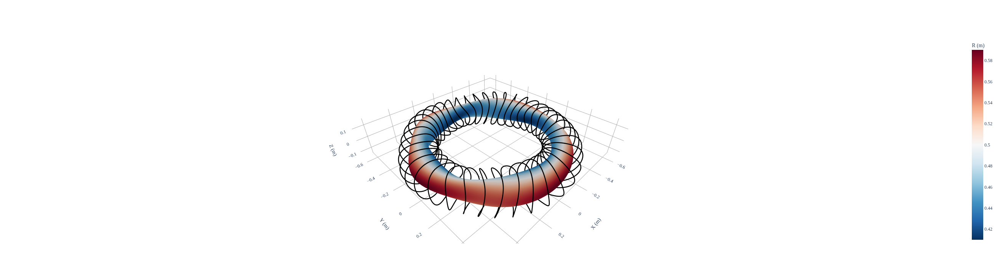

In [22]:
# load saved coil and eq

eq= Equilibrium.load("rot_ellipse_nfp4_e_1p5_a_7p3.h5")
coils = CoilSet.load("rotating_ellipse_coilset.h5")
# coils = "coilset_rotating_ellipse_nfp8.hdf5"
# eq = "eq_rotating_ellipse_nfp8.hdf5"

# remove negative currents, which break the field line trace
for c in coils:
    c.current = np.abs(c.current)

fig = plot_3d(eq, name="R")
fig = plot_coils(coils, fig=fig)
fig.show()

### In this base case, the horizontal plane is on axis

In [23]:
#def flatten_coils(coilset):
#    return [a for i in coilset for a in f(i)]
coils1 = CoilSet.from_symmetry(coils, NFP=eq.NFP, sym=True)

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 4.

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 4.



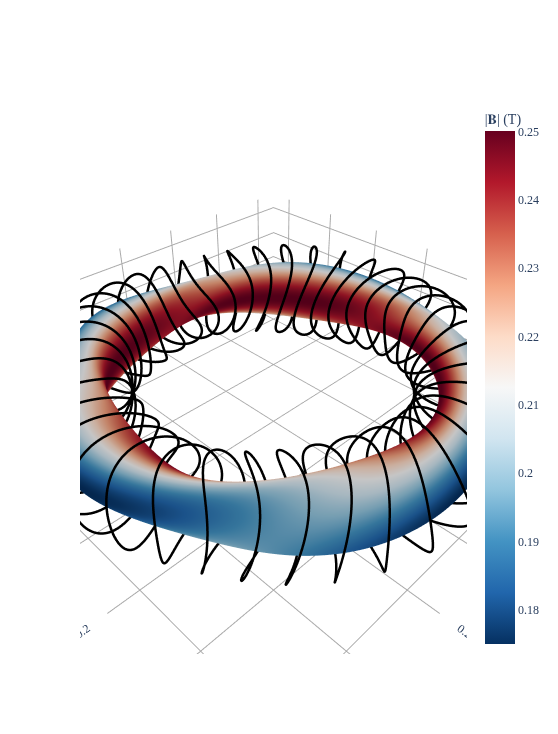

<Figure size 432x288 with 0 Axes>

In [24]:
# rotate to put vertical plane on axis

eq_copy = eq.copy()
eq_copy = rotate_zeta(eq, 0.5*np.pi)
#coils_copy.rotate(angle=1*np.pi/eq.NFP + np.pi/8, axis=[0, 0, 1])


coils_copy = coils1.copy()
coils_copy.rotate(angle = 0.5*np.pi, axis=[0, 0, 1])
#coils_copy.rotate(angle=1*np.pi/8, axis=[0, 0, 1])

plt.figure()
fig = plot_3d(eq_copy, name="|B|", figsize=(10, 10))
fig = plot_coils(coils_copy, fig=fig, figsize=(10, 10))
fig.show()

In [25]:
# roll 90 deg from X-axis to Y-axis if necessary
#coils_copy.rotate(angle=np.pi/2, axis=(0,0,1))

N = len(coils_copy) // 2
coil_2 = CoilSet(coils_copy[:N])
coil_1 = CoilSet(coils_copy[N:])

coil_1 = coil_1.to_FourierXYZ(N=5)
coil_2 = coil_2.to_FourierXYZ(N=5)

fig = plot_coils(coil_1, color='red')
fig = plot_coils(coil_2, color='blue', fig=fig)
fig.show()

In [26]:
# Translate coils

L_over_R = 1.52
R0 = eq.compute("R0")["R0"]

L = L_over_R * R0
coil_2.translate([-L, 0, 0])
coil_1.translate([L, 0, 0])

fig = plot_coils(coil_1, color='red')
fig = plot_coils(coil_2, color='blue', fig=fig)
fig.show()

In [27]:
coilset_fb = CoilSet.load("coilset_SLAM0_nr3_nz2_5Blue_4L2_pairs_Brown250A.h5")
plot_coils(coilset_fb)

In [28]:
# create mirror coils
### new version with stellarator symmetry

I = 2000
N = 5  # number of coils
R1 = 0.18

coilset_fb = CoilSet.load("coilset_SLAM0_nr3_nz2_5Blue_4L2_pairs_Brown250A.h5")

mir_coils = []
for x in np.arange(0, 3):
    mir_coils.append(coilset_fb[x])

#coil_list40 = [coil for coil in mir_coils[0][:]] 
#coil_list41 = [coil for coil in mir_coils[1][:]] 

coil_list40 = []
coil_list41 = []
coil_list42 = []


for coil in mir_coils[0][:]:
    coil.current = 2800
    coil.translate([0.044, 0.,0.])
    coil_list40.append(coil)

for coil in mir_coils[1][:]:
    coil.current = 2800
    coil_list41.append(coil)

for coil in mir_coils[2][::2]:
    coil.current = 2800
    coil_list42.append(coil)

#coil_list42 = [coil for coil in mir_coils[2][::2]] 

print(mir_coils[2])

coil_list40.extend(coil_list41)
coil_list40.extend(coil_list42)


coil_4 = CoilSet(coil_list40, NFP=2, sym=True)

#print(mir_coils[0][1])

shaping_coil = FourierPlanarCoil(
    current = I, 
    center=[-0.70, -R0, 0],   # offset in Y by -R
    normal=[-1, 0, 0],    # flip the normal for return field
    r_n=[R1],
)
shaping_coil = shaping_coil.to_FourierXYZ(N=3)
coil_3 = CoilSet(shaping_coil, NFP=2, sym=True)

# shaping_coil = FourierPlanarCoil(
#     current = I, 
#     center=[-0.5, -R0, 0],   # offset in Y by -R
#    normal=[-1, 0, 0],    # flip the normal for return field
#    r_n=[R1],
#)
#shaping_coil = shaping_coil.to_FourierXYZ(N=2)
#coil_7 = CoilSet(shaping_coil, NFP=2, sym=True)


#mir_coils2 = []
#for x in np.arange(19, 22):

#mir_coils2.append(coilset_fb[x])

#coil_5 = MixedCoilSet([mir_coils2])

limiter_coil = FourierPlanarCoil(
    current = 0., 
    center=[-0.68, -R0-0.01, 0],   # offset in Y by -R
    normal=[-1, 0, 0],    # flip the normal for return field
    r_n=[0.11],
)

coil_6 = CoilSet([limiter_coil], NFP=2, sym=True)

coil_sys = MixedCoilSet( [coil_1, coil_2, coil_3, coil_4, coil_6])

fig = plot_coils(coil_1, color='red', figsize=(10, 10))
fig = plot_coils(coil_2, color='blue',  fig=fig, figsize=(10, 10))
fig = plot_coils(coil_3, color='black', fig=fig, figsize=(10, 10))
fig = plot_coils(coil_4, color='green', fig=fig, figsize=(10, 10))
#fig = plot_coils(coil_5, color='green', fig=fig, figsize=(10, 10))
fig = plot_coils(coil_6, color='orange',fig=fig, figsize=(10, 10))
#fig = plot_coils(coil_7, color='black', fig=fig, figsize=(10, 10))

fig.show()

MixedCoilSet at 0x7fd5d1383cb0 (name=, with 6 submembers)


In [29]:
# from desc.io import load
# qfm_surf1 = load("qfm_surf1_fb.h5")
# fig = plot_3d(qfm_surf1, name="R", fig=fig, figsize=(10, 10))
# plot_coils(coilsetfig=fig)

[1.26058111 1.24784512 1.23505016 1.22218654 1.20924887 1.19623597
 1.18315076 1.17      ] [0. 0. 0. 0. 0. 0. 0. 0.]


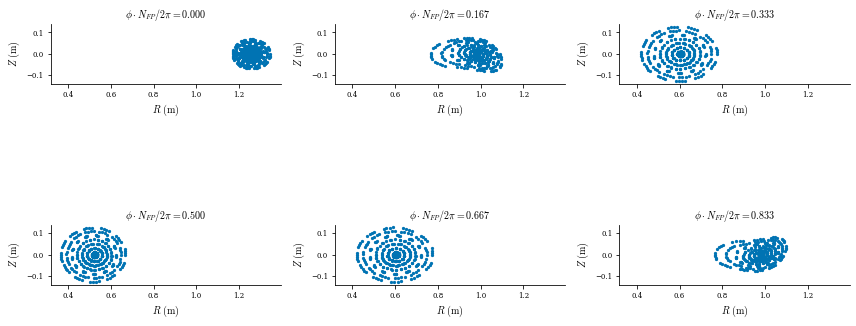

In [30]:
### poincare plot SLAM

# Starting points on the outboard midplane from the equilibrium flux surfaces
grid_trace = LinearGrid(rho=np.linspace(0.0, 1.0, 8))
r0 = eq.compute("R", grid=grid_trace)["R"] + L
z0 = eq.compute("Z", grid=grid_trace)["Z"]

print(r0,z0)

fig, ax, data = poincare_plot(
    coil_sys,       # field is the FIRST positional argument
    r0,
    z0,
    ntransit=50,
    NFP=2,  # use eq.NFP not a hardcoded number
    bounds_R = (0.2, 1.8),
    bounds_Z = (-0.5, 0.5),
    return_data=True,
)

#fig.savefig("poincare-rotating-slam2.png")


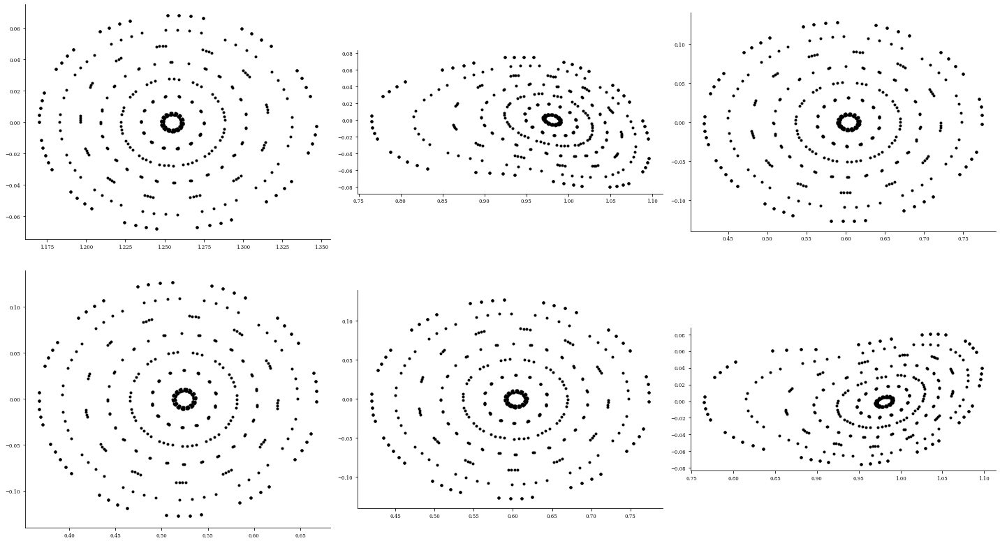

In [31]:
Rp = data['R']
Zp = data['Z']

fig,axs = plt.subplots(2,3, figsize=(20,12))

ax = axs.flatten()
for r in range(10):
    for t in range(6):
        ax[t].plot(Rp[:,t,r], Zp[:,t,r],'.k')

for a in ax:
    a.set_aspect('equal')

In [32]:
'''
now axisymmetrize

===

I'm learning. There are 3 steps.

First get the magnetic axis, a line. This can be got from field line trace from (r0,z0) a good axis guess.
Then inflate the line into a toroidal surface.

Using optimization, morph that surface into a field line flux surface.

Now the elongation of that flux surface is used as an objective to manipulate coils.

===


Is there a better way? I already have these poincare plots? Can't I turn that into the field line flux surface directly?
If there is a toroidal sparsity issue, I can certainly run fieldline_integrate INSTEAD of poincare plot. Same compute, more data.
'''

"\nnow axisymmetrize\n\n===\n\nI'm learning. There are 3 steps.\n\nFirst get the magnetic axis, a line. This can be got from field line trace from (r0,z0) a good axis guess.\nThen inflate the line into a toroidal surface.\n\nUsing optimization, morph that surface into a field line flux surface.\n\nNow the elongation of that flux surface is used as an objective to manipulate coils.\n\n===\n\n\nIs there a better way? I already have these poincare plots? Can't I turn that into the field line flux surface directly?\nIf there is a toroidal sparsity issue, I can certainly run fieldline_integrate INSTEAD of poincare plot. Same compute, more data.\n"

In [33]:
# ### field line trace to get a surface
# # Starting points on the outboard midplane from the equilibrium flux surfaces
# grid_trace = LinearGrid(rho=np.linspace(0.0, 0.5, 4))
# r0 = eq.compute("R", grid=grid_trace)["R"] + L
# z0 = eq.compute("Z", grid=grid_trace)["Z"]

# j = -1

# nturns = 50
# npoints_per_turn = 128
# phi_full = np.linspace(0, 2 * np.pi * nturns, nturns * npoints_per_turn+1)
# rf, zf = field_line_integrate(
#                r0[j], z0[j], 
#                phis=phi_full, field=coil_sys, 
#                bounds_R = (1.0, 10.0),
#                bounds_Z = (-1.5, 1.5),
# )


# xf = np.cos(phi_full) * rf
# yf = np.sin(phi_full) * rf

# plt.figure()
# plt.plot(xf,yf)

# '''
# OK this works, but Rahul's way is better.
# Because tracing field lines is expensive. But using a single fieldline to generate an axis and blowing it into a dummy torus for flux fitting is cheaper (?!).
# '''

In [47]:
### field line trace to get an axis

# Starting points on the outboard midplane from the equilibrium flux surfaces
grid_trace = LinearGrid(rho=np.linspace(0.0, 0.5, 4))
r0 = eq.compute("R", grid=grid_trace)["R"] + L
z0 = eq.compute("Z", grid=grid_trace)["Z"]

j = 0

nturns = 1
npoints_per_turn = 128
phi_full = np.linspace(0, 2 * np.pi * nturns, nturns * npoints_per_turn+1)
ra, za = field_line_integrate(
               r0[j], z0[j], 
               phis=phi_full, field=coil_sys, 
               bounds_R = (0.3, 10.0),
               bounds_Z = (-1.5, 1.5),
)


### from 1D axis construct a 2D dummy surface
theta = np.linspace(0., 2*np.pi, 256)
theta_2D, phi_2D = np.meshgrid(theta, phi_full, indexing="ij")


a_rad = 0.05
rs = ra[None, :] + 1.5*a_rad*np.cos(theta_2D)
zs = za[None, :] + 1*a_rad*np.sin(theta_2D)
#print(r.shape, phi_2D.shape, z.shape)
#coords = np.vstack([rs.flatten(), phi_2D.flatten(), zs.flatten()]).T
coords = np.column_stack([rs.flatten(), phi_2D.flatten(), zs.flatten()])


### Create a Fourier Object for optimization
M0 = 4 #10
N0 = 14 #12
surf0 = FourierRZToroidalSurface.from_values(coords=coords, theta=theta_2D.flatten(), M=M0, N=N0, NFP=2, sym=True, rcond=1e-7)


#plot_boundary(surf0)
fig = plot_coils(coil_sys)
fig = plot_3d(surf0, name="R", fig=fig)
fig.show()



/pscratch/sd/r/rgaur/DESC/desc/geometry/surface.py:153: UserWarning:

Left handed coordinates detected, switching sign of theta. To avoid this warning in the future, switch the sign of all modes with m<0. You may also need to switch the sign of iota or current profiles.

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



In [48]:

# define qflux surface
qflux = SurfaceQuadraticFlux(
    surf0,
    coil_sys,
    eval_grid=LinearGrid(M=20, N=26, NFP=surf0.NFP),
    field_fixed=True,  # field is not being optimized
    bs_chunk_size=10,
    weight=9e-2
)

# define target flux
target_psi = -2.2e-3
tflux = ToroidalFlux(
    surf0,
    coil_sys,
    target=target_psi,  # the same toroidal flux as used in the free bdry eq
    eq_fixed=False,  # we will allow the thing passed in (QFM surface in this case) to vary
    field_fixed=True,  # field is not being optimized, so we fix it
    weight=1e3
)

'''
Should flux be pos or neg?
seems like neg gives better results, but neither is very good
'''

'\nShould flux be pos or neg?\nseems like neg gives better results, but neither is very good\n'

In [49]:
djin = tflux.build()

Precomputing transforms


Building objective: Surface Quadratic Flux
Precomputing transforms
Timer: Precomputing transforms = 504 ms
Timer: Objective build = 532 ms
Number of parameters: 261
Number of objectives: 2174
Timer: Initializing the optimization = 583 ms

Starting optimization
Using method: lsq-exact
Solver options:
------------------------------------------------------------
Maximum Function Evaluations       : 1001
Maximum Allowed Total Δx Norm      : inf
Scaled Termination                 : True
Trust Region Method                : qr
Initial Trust Radius               : 5.856e-01
Maximum Trust Radius               : inf
Minimum Trust Radius               : 2.220e-16
Trust Radius Increase Ratio        : 2.000e+00
Trust Radius Decrease Ratio        : 2.500e-01
Trust Radius Increase Threshold    : 7.500e-01
Trust Radius Decrease Threshold    : 2.500e-01
------------------------------------------------------------ 

   Iteration     Total nfev        Cost      Cost reduction    Step norm     Optimality

(<Figure size 1152x576 with 1 Axes>,
 <Axes: xlabel='$R ~(\\mathrm{m})$', ylabel='$Z ~(\\mathrm{m})$'>)

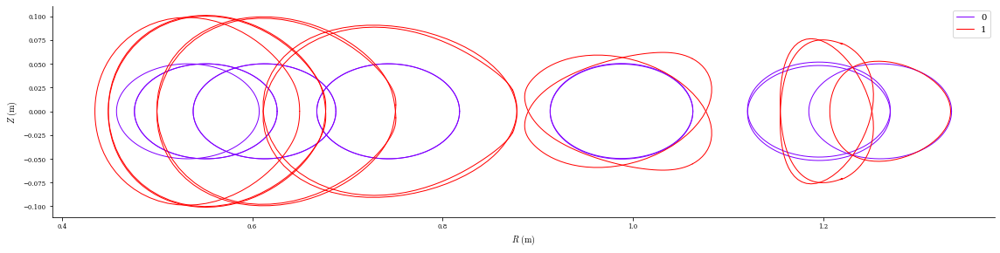

In [50]:
obj = ObjectiveFunction((qflux, tflux))
opt = Optimizer("lsq-exact")

# do optimization
(qfm_surf1,), _ = opt.optimize(
    surf0,
    objective=obj,
    #constraints=constraints,
    #x_scale="ess",
    ftol=1e-8,
    maxiter=200,
    verbose=3,
    copy=True,
)

# report results visually
plot_boundaries([surf0, qfm_surf1], phi=12, figsize=(16,8))

In [53]:
fig = plot_coils(coil_sys)
fig = plot_3d(qfm_surf1, name="R", fig=fig)
fig.show()

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



In [52]:
#coil_sys.save("coil_sys_fb.h5")
#qfm_surf1.save("qfm_surf1_fb.h5")
surf0.save("qfm_surf0_fb_1p52_psi2p2e-3_B1s.h5")

# from desc.io import load
# #coil_sys = load("coil_sys_fb.h5")
# qfm_surf1 = load("qfm_surf1_fb.h5")

Building objective: Surface Quadratic Flux
Precomputing transforms
Timer: Precomputing transforms = 43.1 ms
Building objective: toroidal-flux
Precomputing transforms
Timer: Precomputing transforms = 38.4 ms
Building objective: SLAM elongation
Precomputing transforms


/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



Timer: Precomputing transforms = 49.6 ms
Building objective: SLAM center
Precomputing transforms


/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



Timer: Precomputing transforms = 58.0 ms
Building objective: Surface Match
Precomputing transforms


/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



Timer: Precomputing transforms = 24.2 ms
Building objective: coil-coil minimum distance
Building objective: coil length
Precomputing transforms
Timer: Precomputing transforms = 23.5 ms
Building objective: plasma-coil minimum distance
Building objective: elongation
Precomputing transforms
Timer: Precomputing transforms = 44.4 ms
Timer: Objective build = 3.27 sec
Building objective: fixed parameters
Building objective: fixed shift
Building objective: fixed rotation
Timer: Objective build = 917 ms
Timer: LinearConstraintProjection build = 623 ms
Number of parameters: 282
Number of objectives: 1467
Timer: Initializing the optimization = 4.82 sec

Starting optimization
Using method: lsq-exact
Solver options:
------------------------------------------------------------
Maximum Function Evaluations       : 12501
Maximum Allowed Total Δx Norm      : inf
Scaled Termination                 : True
Trust Region Method                : qr
Initial Trust Radius               : 3.338e+01
Maximum Trust

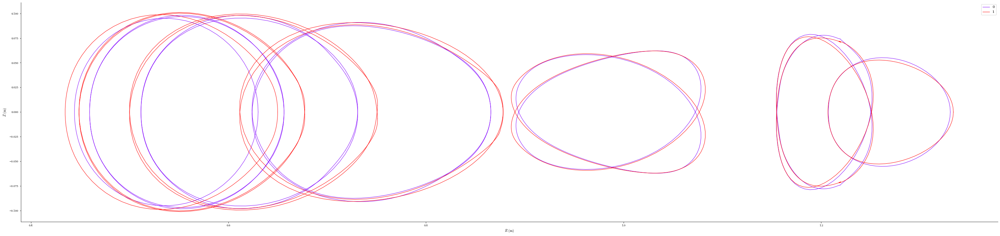

In [61]:
### Axisymmetrization
'''
There is a LinearGrid called Elongation grid.

there is a surface called surf0 
and a coilset called field2

an Objective Function is defined called obj
an Optimizer is defined called opt


'''
NFP0 = 2
#surf0 = qfm_surf1.copy()
### target_psi = -0.0505 # use the target_psi from initial surface fit. More robust than redefining here.

Elongation_grid = LinearGrid(M = 24, zeta=np.array([np.pi/2]), rho=np.array([1.0]), NFP=NFP0, sym=False, axis=False)
coil_grid = LinearGrid(N=20)
#coilset2[2] = coilset2[2].change_resolution(N=1)
#coilset2[3] = coilset2[3].change_resolution(N=1)

# grid for SLAMElongation: a toroidal wedge that isolates ONE X0=0.4 cross-section
theta_s = np.linspace(0, 2*np.pi, 128, endpoint=False)
zeta_s  = np.linspace(np.pi/8, np.pi/2, 128, endpoint=True)   # as in your prototype
SLAM_grid = LinearGrid(theta=theta_s, zeta=zeta_s, NFP=1, sym=False)

#surfacet_grid = LinearGrid(rho=1.0, theta = np.linspace(0, 2*np.pi, 20), zeta=np.array([0.]), sym=False, NFP=1) 
zeta0 = np.array([-np.pi/8, -np.pi/8 + 0.1, -0.2, 0., 0.2, np.pi/8 - 0.1, np.pi/8])
#zeta0 = np.array([-np.pi/8 + 0.1, -0.2, 0., 0.2, np.pi/8 - 0.1])

#surfacet_grid = LinearGrid(rho=1.0, theta = np.linspace(0, 2*np.pi, 20), zeta=np.linspace(-np.pi/4 + 0.2, np.pi/4 - 0.2, 7),  sym=False, NFP=1) 
surfacet_grid = LinearGrid(rho=1.0, theta = np.linspace(0, 2*np.pi, 22), zeta=zeta0,  sym=False, NFP=1) 


target_volume = 0.135
#target_volume = 0.16

bounds_length = (
    0.0,
    [
        4*np.pi, # fixed
        4*np.pi, # fixed
        2*np.pi*0.4, # un-fixed later
        4*np.pi, # fixed
        4*np.pi,
        #4*np.pi,
        #2*np.pi*0.4,
    ],
)

coil_sys[2].current = 3000


obj = ObjectiveFunction((SurfaceQuadraticFlux(surf0, coil_sys, eval_grid=LinearGrid(M=20, N=24, NFP=NFP0, sym=True), field_fixed=False, bs_chunk_size=64,weight=4.5), 
                         ToroidalFlux(surf0, coil_sys, target=target_psi, eq_fixed=False, field_fixed=False, weight=12),
                        SLAMElongation(surf0, X0=[0.04, 0.2, 0.4, 0.6], bounds=(1.0, 1.001), grid=SLAM_grid, weight=4.0),
                        SLAMCenter(surf0, X0=[0.04, 0.2, 0.4, 0.55], Y0=[0.5, 0.5, 0.5, 0.5], Z0=[0., 0., 0., 0.], grid=SLAM_grid, weight=2.5),
                         ##Volume(surf0, target=target_volume, weight=5e0),
                        SurfaceMatch(surf0, qfm_surf1, surfacet_fixed=True, surfacet_grid=surfacet_grid, weight=1.2),
                        CoilSetMinDistance(coil_sys,bounds=(0.04,1000),grid=coil_grid, weight=10),
                        CoilLength(coil_sys, bounds=bounds_length, normalize_target=True, weight=20, grid=coil_grid),
                        ##CoilCurvature(field2, bounds=(-58.5, 105),normalize_target=False, grid=coil_grid,weight=10),
                        PlasmaCoilSetMinDistance(surf0, coil_sys, bounds=(0.014, np.inf), normalize_target=True, plasma_grid=LinearGrid(M=24, N=32, NFP=NFP0, sym=True), coil_grid=coil_grid, eq_fixed=False, weight=1000),
                         Elongation(eq=surf0, bounds=(1.0, 1.005), grid=Elongation_grid, weight=2.0),
                        ))


constraints = (FixParameters(coil_sys,[{"X_n":True,"Y_n": True,"Z_n":True, "current":True},\
                                       {"X_n":True,"Y_n": True,"Z_n":True, "current":True},\
                                       #{"r_n":False, "center":False, "normal":False, "current":False},\
                                       #{"X_n":[1], "Y_n":[0], "center":True, "normal":True, "current":True},\
                                       #{"X_n":False, "Y_n":False, "center":True, "normal":True, "current":False},\
                                       {"current":True},\
                                       {"r_n":True, "center":True, "normal":True, "current":True},\
                                       {"r_n":True, "center":True, "normal":True, "current":True}],))
                                       #{"r_n":True, "center":True, "normal":True, "current":True}),)

#constraints = (FixParameters(coilset2,[{}, {}, {"r_n":False, "center":False, "normal":False},\
#                     {"r_n":False, "center":False, "normal":False}, {}, {}]),)
#constraints = ((FixParameters(field,[{}, {}, {}, {}, {}, {}]),))

#obj.build()
#obj.compile()

#opt = Optimizer("lsq-auglag")
opt = Optimizer("lsq-exact")
#opt = Optimizer("proximal-lsq-exact")

[qfm_surf,field2_opt], _ = opt.optimize(
    [surf0, coil_sys],
    objective=obj,
    constraints=constraints,
    #x_scale="ess",
    ftol=1e-10,
    xtol=1e-20,
    gtol=1e-20,
    maxiter=2500,
    verbose=3,
    copy=True,
)

### plot
fig, ax = plot_boundaries([qfm_surf, qfm_surf1], phi=12, figsize=(40, 40))
fig.show()

In [62]:
field2_opt.save("SLAM0_coilset_fb_1p52_psi2p2e-3_B1s.h5")
qfm_surf.save("qfm_surf_fb_1p52_psi2p2e-3_B1s.h5")

fig = plot_3d(qfm_surf, name="R")
fig = plot_coils(field2_opt, fig=fig, )
fig.show()

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



In [63]:
eq1 = Equilibrium(surface=qfm_surf)
from desc.vmec import VMECIO
VMECIO.save(eq1, path="wout_SLAM0_bdry_fb_1p52_psi2p2-3_B1s.nc", M_grid=24, N_grid=32, surfs=32)

/pscratch/sd/r/rgaur/DESC/desc/equilibrium/initial_guess.py:231: UserWarning:

Surfaces from initial guess are not nested, attempting to refine coordinates. This may take a few moments.

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Surfaces still not nested after refinement. This is possibly because the boundary contains self-intersections or other singularities, or because the refinement requires more iterations. You may need to manually adjust the initial guess or do further refinement using the GoodCoordinates objective.



Computing data
Saving parameters
Saving R
Saving Z
Saving lambda
Saving Jacobian
Saving |B|
Saving B^theta
Saving B^zeta
Saving B_psi
Saving B_theta
Saving B_zeta
Saving J^theta*sqrt(g)
Saving J^zeta*sqrt(g)


[1.26058111 1.23675995 1.21270629 1.18839317] [0. 0. 0. 0.]


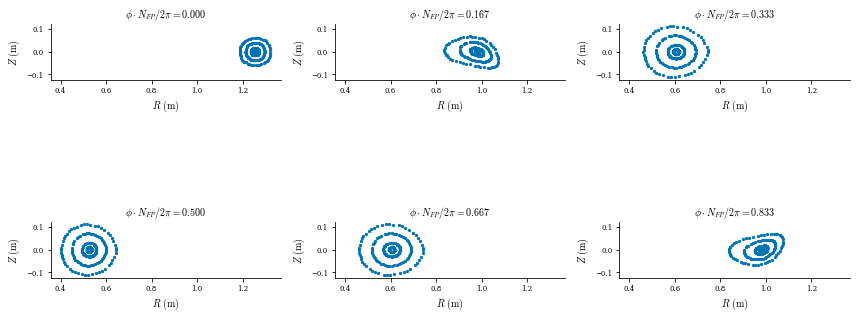

In [68]:
### poincare plot SLAM
# Starting points on the outboard midplane from the equilibrium flux surfaces
grid_trace = LinearGrid(rho=np.linspace(0.0, 0.8, 4))
r0 = eq.compute("R", grid=grid_trace)["R"] + L
z0 = eq.compute("Z", grid=grid_trace)["Z"]

print(r0,z0)

fig, ax, data = poincare_plot(
    field2_opt,       # field is the FIRST positional argument
    r0,
    z0,
    ntransit=50,
    NFP=2,  # use eq.NFP not a hardcoded number
    bounds_R = (0.2, 1.8),
    bounds_Z = (-0.5, 0.5),
    return_data=True,
)
#fig.savefig("poincare-rotating-slam2.png")

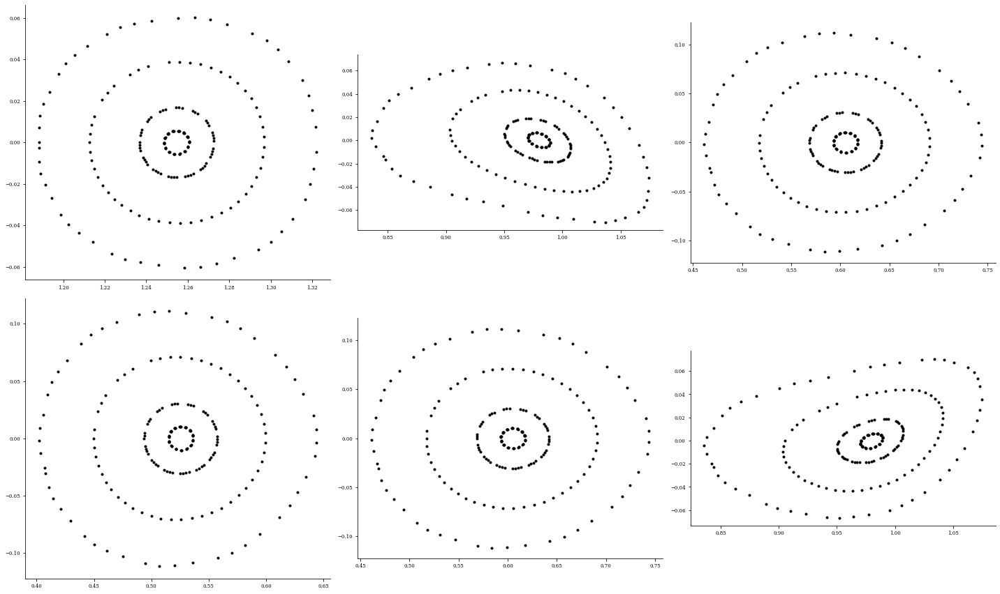

In [69]:
Rp = data['R']
Zp = data['Z']

fig,axs = plt.subplots(2,3, figsize=(20,12))

ax = axs.flatten()
for r in range(4):
    for t in range(6):
        ax[t].plot(Rp[:,t,r], Zp[:,t,r], '.k')

for a in ax:
    a.set_aspect('equal')

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



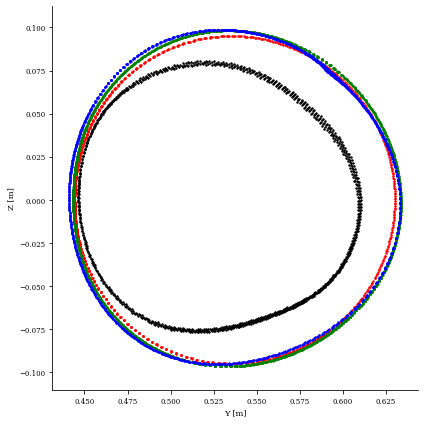

In [66]:
from desc.vmec import VMECIO
from desc.io import load

##qfm_surf = VMECIO.load("wout_SLAM0_bdry_fb_1p52_psi2p2-3_E4.nc").surface
##surf = qfm_surf.copy()
surf = load("qfm_surf_fb_1p52_psi2p2e-3_B1s.h5")
ntheta, nphi = 256, 256
theta = np.linspace(0, 2 * np.pi, ntheta, endpoint=False)
zeta  = np.linspace(np.pi/8, np.pi/2, nphi,  endpoint=False)   # full torus, NFP=1 coverage
grid = LinearGrid(theta=theta, zeta=zeta, NFP=1, sym=False)

# --- compute R, phi, Z on the grid ---
data = surf.compute(["R", "phi", "Z"], grid=grid)
R   = data["R"]
phi = data["phi"]     # cylindrical toroidal angle (= zeta for an RZ surface)
Z   = data["Z"]

# --- convert to Cartesian ---
X = R * np.cos(phi)
Y = R * np.sin(phi)
# Z is already Z

plt.figure(figsize=(6, 6))

# --- Y-Z cross section at constant X ---
X0  = 0.0                              # plane you want to slice at
tol = 0.01 * (X.max() - X.min())           # thin slab thickness; tune as needed
mask = np.abs(X - X0) < tol
plt.scatter(Y[mask], Z[mask], color='r', s=2)


# --- Y-Z cross section at constant X ---
X0  = 0.2                              # plane you want to slice at
tol = 0.01 * (X.max() - X.min())           # thin slab thickness; tune as needed
mask= np.abs(X - X0) < tol
plt.scatter(Y[mask], Z[mask], color='g', s=2)


# --- Y-Z cross section at constant X ---
X0  = 0.4                              # plane you want to slice at
tol = 0.01 * (X.max() - X.min())           # thin slab thickness; tune as needed
mask = np.abs(X - X0) < tol
plt.scatter(Y[mask], Z[mask], color='b', s=2)


# --- Y-Z cross section at constant X ---
X0  = 0.65                              # plane you want to slice at
tol = 0.01 * (X.max() - X.min())           # thin slab thickness; tune as needed
mask = np.abs(X - X0) < tol
plt.scatter(Y[mask], Z[mask], color='k', s = 2)

plt.xlabel("Y [m]")
plt.ylabel("Z [m]")
#plt.title(f"Y-Z cross section at X = {X0:.3f} (slab ±{tol:.3f})")
plt.axis("equal")
plt.tight_layout()
plt.show()

In [67]:
field2_opt = load("SLAM0_coilset_fb_1p52_psi2p2e-3_B1s.h5")
qfm_surf = load("qfm_surf_fb_1p52_psi2p2e-3_B1s.h5")

fig = plot_3d(qfm_surf, name="R")
fig = plot_coils(field2_opt, fig=fig, figsize=(20, 20))
fig.show()

/pscratch/sd/r/rgaur/DESC/desc/utils.py:563: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



##### from desc.io import load
field2_opt = load("SLAM0_coilset_fb_1p52_psi2p2e-3_B8.h5")
qfm_surf = load("qfm_surf_fb_1p52_psi2p2e-3_B8.h5")

fig = plot_3d(qfm_surf, name="R")
fig = plot_coils(field2_opt, fig=fig, figsize=(20, 20))
fig.show()